## 1. Busniness Understanding

- Use Irirs dataset
- Silhouette Score
- Calinski–Harabasz Score


## 2. Data Collection

#### 2.1 Import necessary library and datasets

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score,calinski_harabasz_score

iris_data = load_iris()
iris_data_df = pd.DataFrame(iris_data.data,columns = iris_data.feature_names)

## 3. Data Understanding

In [2]:
iris_data_df.shape

(150, 4)

In [3]:
iris_data_df.isna().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [4]:
iris_data_df.duplicated().unique()

array([False,  True])

In [5]:
iris_data_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 4. Data Preparation

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(iris_data_df)

## 5. Model Building 

#### Step 1 Building Cluster Algorithm

In [7]:
km_cluster = KMeans(n_clusters=3,random_state=40)
km_cluster.fit_predict(X_scaled)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 2,
       2, 0, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

#### to find centroids

In [8]:
km_cluster.cluster_centers_

array([[-0.01139555, -0.87600831,  0.37707573,  0.31115341],
       [-1.01457897,  0.85326268, -1.30498732, -1.25489349],
       [ 1.16743407,  0.14530299,  1.00302557,  1.0300019 ]])

### How to decide optimal number of clusters?

In [9]:
results = []
for i in range(2,11):
    km_cluster = KMeans(n_clusters=i,random_state=40)
    labels = km_cluster.fit_predict(X_scaled)
    sil_score = silhouette_score(X_scaled,labels)
    cal_score = calinski_harabasz_score(X_scaled,labels)
    results.append({"k":i,
                    "Sil Score":sil_score,
                    "Cal Score":cal_score})
pd.DataFrame(results)

,k,Sil Score,Cal Score
0,2,0.581750,251.349339
1,3,0.463042,241.426323
2,4,0.393134,178.209127
3,5,0.377764,168.441965
4,6,0.319026,180.776241
5,7,0.339178,175.086921
6,8,0.334652,161.689187
7,9,0.310427,149.156578
8,10,0.344612,161.223620


In [10]:
wcss = []
for i in range(1,11):
    km_cluster = KMeans(n_clusters=i,random_state=40)
    km_cluster.fit_predict(X_scaled)
    wcss.append(km_cluster.inertia_)
wcss

[600.0000000000001,
 222.36170496502305,
 140.0327527742865,
 128.70478375494054,
 106.25722393088087,
 82.45209444611595,
 71.88810447057082,
 66.88520499700402,
 63.406283537405045,
 52.79656548416761]

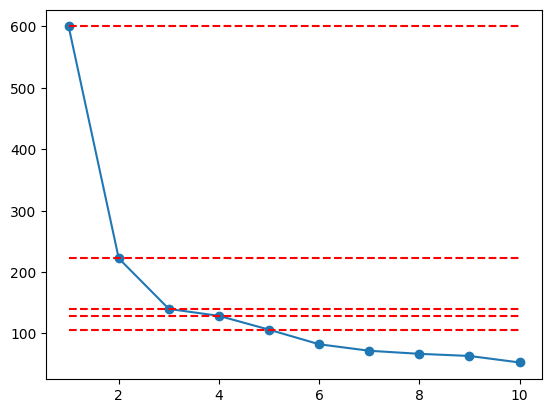

In [11]:
plt.plot(range(1,11),wcss,marker='o')
plt.hlines(wcss[0:5],xmin= 1, xmax = 10,linestyles = "dashed",colors="red")

### Step 2 Attach clusters to dataset and Analyse Cluster and categorize

#### 1. Attach clusters to dataset

In [12]:
km_cluster = KMeans(n_clusters=3,random_state=40)
labels = km_cluster.fit_predict(X_scaled)

In [13]:
#we need to use X becoz College data have catergerical data(Dataname) with that we can't catergorize so better agg with numerical fetures
iris_data_df["iris_class"] = labels
iris_data_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),iris_class
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


#### 2. Analyse Cluster and categorize - Data mining 

In [14]:
iris_data_df.groupby(by = "iris_class").agg(["mean"])

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
,mean,mean,mean,mean
iris_class,,,,
0,5.833929,2.676786,4.421429,1.435714
1,5.006000,3.428000,1.462000,0.246000
2,6.806818,3.120455,5.522727,1.981818


In [15]:
iris_data_df.groupby(by = "iris_class").agg(["min","max"])

sepal length (cm)      sepal width (cm)      petal length (cm)  \
                         min  max              min  max               min   
iris_class                                                                  
0                        4.9  6.7              2.0  3.0               3.0   
1                        4.3  5.8              2.3  4.4               1.0   
2                        5.9  7.9              2.6  3.8               4.4   

                petal width (cm)       
            max              min  max  
iris_class                             
0           5.8              1.0  2.4  
1           1.9              0.1  0.6  
2           6.9              1.4  2.5

In [16]:
cluster_names = {0:"Iris versicolor",
                1:"Iris setosa",
                2:"Iris virginica"
               }
iris_data_df["Category"] = iris_data_df["iris_class"].map(cluster_names)
iris_data_df


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),iris_class,Category
0,5.1,3.5,1.4,0.2,1,Iris setosa
1,4.9,3.0,1.4,0.2,1,Iris setosa
2,4.7,3.2,1.3,0.2,1,Iris setosa
3,4.6,3.1,1.5,0.2,1,Iris setosa
4,5.0,3.6,1.4,0.2,1,Iris setosa
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,Iris virginica
146,6.3,2.5,5.0,1.9,0,Iris versicolor
147,6.5,3.0,5.2,2.0,2,Iris virginica
148,6.2,3.4,5.4,2.3,2,Iris virginica


In [17]:
X_input = iris_data_df.drop(["iris_class","Category"],axis = 1)
y = iris_data_df["iris_class"]


#### Step 3 Transition to supervised learning

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report

X_train, X_test, y_train, y_test  = train_test_split(X_input,y,test_size=.2,random_state=39,shuffle=True,stratify=y)


rf_classifier = RandomForestClassifier(n_estimators=50)
rf_classifier.fit(X_train, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [19]:
y_pred_train = rf_classifier.predict(X_train)
y_pred_test = rf_classifier.predict(X_test)


print("Train Accuracy Score",accuracy_score(y_train,y_pred_train))
print("Test Accuracy Score",accuracy_score(y_test,y_pred_test))

print("Train Classification report \n",classification_report(y_train,y_pred_train))
print("Test Classification report \n",classification_report(y_test,y_pred_test))

Train Accuracy Score 1.0
Test Accuracy Score 0.9
Train Classification report 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       1.00      1.00      1.00        40
           2       1.00      1.00      1.00        35

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120

Test Classification report 
               precision    recall  f1-score   support

           0       0.90      0.82      0.86        11
           1       1.00      1.00      1.00        10
           2       0.80      0.89      0.84         9

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

